# Thí nghiệm 3: Xây dựng golden vectors cho TinyCAE INT8

## Mục tiêu

Thí nghiệm tạo bộ dữ liệu tham chiếu cho 20 ảnh hardware test. Mỗi mẫu gồm ảnh RGB888 gốc, tensor đầu vào INT8, latent INT8 1.024 byte và ảnh tái tạo bằng decoder FP32. Golden vectors là chuẩn đối chiếu độc lập khi cùng model được thực thi trên ESP32.

## 1. Thiết lập dữ liệu và hiện vật

Các hiện vật đầu vào gồm manifest 20 ảnh, encoder TFLite INT8, model manifest và decoder FP32. Kết quả được lưu tách biệt trong `bitstreams/tinycae/golden` và `results`.

In [1]:
from pathlib import Path
import csv
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
HARDWARE_DIR = PROJECT_ROOT / 'data' / 'processed' / 'hardware_test'
HARDWARE_MANIFEST = HARDWARE_DIR / 'manifest.csv'
TFLITE_PATH = PROJECT_ROOT / 'models' / 'tinycae' / 'int8' / 'encoder_int8.tflite'
MODEL_MANIFEST_PATH = PROJECT_ROOT / 'manifests' / 'model_manifest.json'
DECODER_PATH = PROJECT_ROOT / 'models' / 'tinycae' / 'stratified_baseline' / 'decoder.keras'
OUTPUT_DIR = PROJECT_ROOT / 'bitstreams' / 'tinycae' / 'golden'
RESULTS_PATH = PROJECT_ROOT / 'results' / 'tinycae_golden_20.csv'
SUMMARY_PATH = PROJECT_ROOT / 'results' / 'tinycae_golden_20_summary.json'

for path in [HARDWARE_MANIFEST, TFLITE_PATH, MODEL_MANIFEST_PATH, DECODER_PATH]:
    print(path, '->', path.exists())
    assert path.exists(), path

d:\projects\iot-final\data\processed\hardware_test\manifest.csv -> True
d:\projects\iot-final\models\tinycae\int8\encoder_int8.tflite -> True
d:\projects\iot-final\manifests\model_manifest.json -> True
d:\projects\iot-final\models\tinycae\stratified_baseline\decoder.keras -> True


## 2. Xác minh tính toàn vẹn của model

SHA-256 và kích thước encoder được đối chiếu với model manifest. Interpreter sử dụng kernel TFLite tham chiếu, không sử dụng delegate XNNPACK, nhằm giảm khác biệt số học khi so sánh với TensorFlow Lite Micro. Metadata input/output và tham số lượng tử được đọc trực tiếp từ model.

In [2]:
def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

model_bytes = TFLITE_PATH.read_bytes()
model_manifest = json.loads(MODEL_MANIFEST_PATH.read_text(encoding='utf-8'))
actual_sha256 = sha256_bytes(model_bytes)
print('Model bytes:', len(model_bytes))
print('SHA-256:', actual_sha256)
assert actual_sha256 == model_manifest['encoder_sha256']
assert len(model_bytes) == model_manifest['encoder_bytes']

interpreter = tf.lite.Interpreter(
    model_content=model_bytes,
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES,
)
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]
input_scale, input_zero_point = input_detail['quantization']
output_scale, output_zero_point = output_detail['quantization']
print('Input:', input_detail['shape'], input_detail['dtype'], input_detail['quantization'])
print('Output:', output_detail['shape'], output_detail['dtype'], output_detail['quantization'])
assert input_detail['dtype'] == np.int8
assert output_detail['dtype'] == np.int8
assert tuple(output_detail['shape']) == (1, 8, 8, 16)

Model bytes: 9560
SHA-256: badfe7f849a7d71ba91b87505ba3fc58442df8982c2eee643a626535862bb8c6
Input: [ 1 32 32  3] <class 'numpy.int8'> (0.003921568859368563, -128)
Output: [ 1  8  8 16] <class 'numpy.int8'> (0.004770447965711355, -5)


c:\Users\vubao\miniconda3\envs\iot-tf\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 3. Tập hardware test

Tập phần cứng gồm 20 ảnh CIFAR-10 cố định, đúng hai ảnh cho mỗi lớp. Mỗi ảnh raw phải có kích thước 3.072 byte theo định dạng RGB888, HWC và row-major. `image_id` là khóa liên kết giữa manifest, raw input, latent và kết quả đánh giá.

In [3]:
with HARDWARE_MANIFEST.open(newline='', encoding='utf-8') as stream:
    hardware_records = list(csv.DictReader(stream))

assert len(hardware_records) == 20
for record in hardware_records:
    raw_path = HARDWARE_DIR / 'raw' / f"{record['image_id']}.rgb"
    assert raw_path.exists(), raw_path
    assert raw_path.stat().st_size == 3072
print('Đã xác minh 20/20 ảnh raw RGB888.')

Đã xác minh 20/20 ảnh raw RGB888.


## 4. Pipeline inference tham chiếu

Pipeline chuẩn hóa ảnh RGB888, lượng tử hóa theo input scale/zero point, thực thi encoder INT8 và giải lượng tử latent theo output scale/zero point. Ba hiện vật được duy trì đồng thời để kiểm tra riêng từng giai đoạn của pipeline.

In [4]:
def encode_int8(image_uint8):
    image_float = image_uint8.astype(np.float32) / 255.0
    input_int8 = np.round(image_float / input_scale + input_zero_point)
    input_int8 = np.clip(input_int8, -128, 127).astype(np.int8)
    interpreter.set_tensor(input_detail['index'], input_int8[np.newaxis, ...])
    interpreter.invoke()
    latent_int8 = interpreter.get_tensor(output_detail['index']).copy()[0]
    latent_float = (latent_int8.astype(np.float32) - output_zero_point) * output_scale
    return input_int8, latent_int8, latent_float

## 5. Sinh golden vectors

Mỗi ảnh được inference hai lần trên cùng interpreter; hai latent phải bit-exact để xác nhận tính lặp lại. Checksum SHA-256 được lưu cho input và latent. Decoder FP32 tái tạo ảnh từ latent đã giải lượng tử, sau đó PSNR và SSIM được tính so với ảnh gốc.

In [5]:
decoder = tf.keras.models.load_model(DECODER_PATH, compile=False)
input_dir = OUTPUT_DIR / 'input_int8'
latent_dir = OUTPUT_DIR / 'latent_int8'
reconstruction_dir = OUTPUT_DIR / 'reconstruction_png'
for directory in [input_dir, latent_dir, reconstruction_dir, RESULTS_PATH.parent]:
    directory.mkdir(parents=True, exist_ok=True)

rows = []
for number, record in enumerate(hardware_records, start=1):
    image_id = record['image_id']
    raw_path = HARDWARE_DIR / 'raw' / f'{image_id}.rgb'
    raw_data = raw_path.read_bytes()
    assert hashlib.sha256(raw_data).hexdigest() == record['sha256']
    image_uint8 = np.frombuffer(raw_data, dtype=np.uint8).reshape(32, 32, 3)

    input_int8, latent_int8, latent_float = encode_int8(image_uint8)
    _, latent_repeat, _ = encode_int8(image_uint8)
    assert np.array_equal(latent_int8, latent_repeat), f'{image_id}: inference không lặp lại'
    assert input_int8.nbytes == 3072
    assert latent_int8.nbytes == 1024

    reconstruction = decoder.predict(latent_float[np.newaxis, ...], verbose=0)[0]
    reference = image_uint8.astype(np.float32) / 255.0
    psnr = float(tf.image.psnr(reference, reconstruction, max_val=1.0).numpy())
    ssim = float(tf.image.ssim(reference, reconstruction, max_val=1.0).numpy())

    input_path = input_dir / f'{image_id}.int8'
    latent_path = latent_dir / f'{image_id}.int8'
    reconstruction_path = reconstruction_dir / f'{image_id}.png'
    input_path.write_bytes(input_int8.tobytes(order='C'))
    latent_path.write_bytes(latent_int8.tobytes(order='C'))
    Image.fromarray(np.clip(reconstruction * 255.0, 0, 255).astype(np.uint8), mode='RGB').save(reconstruction_path)

    rows.append({
        'image_id': image_id,
        'class_id': int(record['class_id']),
        'class_name': record['class_name'],
        'input_bytes': input_int8.nbytes,
        'latent_bytes': latent_int8.nbytes,
        'input_sha256': sha256_bytes(input_int8.tobytes()),
        'latent_sha256': sha256_bytes(latent_int8.tobytes()),
        'psnr_db': psnr,
        'ssim': ssim,
    })
    print(f'[{number:02d}/20] {image_id}: PSNR={psnr:.3f} dB, SSIM={ssim:.6f}')

[01/20] cifar10_test_01789: PSNR=34.230 dB, SSIM=0.981418
[02/20] cifar10_test_08563: PSNR=32.331 dB, SSIM=0.963910
[03/20] cifar10_test_03745: PSNR=29.974 dB, SSIM=0.976667
[04/20] cifar10_test_06493: PSNR=31.945 dB, SSIM=0.968731
[05/20] cifar10_test_00776: PSNR=31.123 dB, SSIM=0.975345
[06/20] cifar10_test_03534: PSNR=36.006 dB, SSIM=0.979299
[07/20] cifar10_test_03607: PSNR=32.604 dB, SSIM=0.953335
[08/20] cifar10_test_08241: PSNR=32.903 dB, SSIM=0.967542
[09/20] cifar10_test_06822: PSNR=32.958 dB, SSIM=0.971224
[10/20] cifar10_test_08944: PSNR=30.724 dB, SSIM=0.970559
[11/20] cifar10_test_01922: PSNR=30.622 dB, SSIM=0.988501
[12/20] cifar10_test_08458: PSNR=29.207 dB, SSIM=0.965216
[13/20] cifar10_test_00891: PSNR=27.727 dB, SSIM=0.937892
[14/20] cifar10_test_02862: PSNR=29.088 dB, SSIM=0.930170
[15/20] cifar10_test_07226: PSNR=30.121 dB, SSIM=0.971159
[16/20] cifar10_test_09672: PSNR=29.599 dB, SSIM=0.967639
[17/20] cifar10_test_02604: PSNR=32.444 dB, SSIM=0.976347
[18/20] cifar1

## 6. Tổng hợp kết quả

CSV lưu kết quả theo từng ảnh; JSON tóm tắt ghi checksum model, tham số lượng tử, số mẫu hợp lệ, BPP, tỷ lệ nén, PSNR và SSIM trung bình. Với latent 8 × 8 × 16 INT8, kích thước cố định là 1.024 byte, tương ứng 8 bit/pixel và tỷ lệ nén raw/latent bằng 3:1.

In [6]:
with RESULTS_PATH.open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

summary = {
    'model_sha256': actual_sha256,
    'images': len(rows),
    'passed': len(rows),
    'input_scale': float(input_scale),
    'input_zero_point': int(input_zero_point),
    'output_scale': float(output_scale),
    'output_zero_point': int(output_zero_point),
    'latent_bytes_per_image': 1024,
    'bits_per_pixel': 8.0,
    'compression_ratio': 3.0,
    'mean_psnr_db': float(np.mean([row['psnr_db'] for row in rows])),
    'mean_ssim': float(np.mean([row['ssim'] for row in rows])),
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2))
print('CSV:', RESULTS_PATH)
print('Golden vectors:', OUTPUT_DIR)

{
  "model_sha256": "badfe7f849a7d71ba91b87505ba3fc58442df8982c2eee643a626535862bb8c6",
  "images": 20,
  "passed": 20,
  "input_scale": 0.003921568859368563,
  "input_zero_point": -128,
  "output_scale": 0.004770447965711355,
  "output_zero_point": -5,
  "latent_bytes_per_image": 1024,
  "bits_per_pixel": 8.0,
  "compression_ratio": 3.0,
  "mean_psnr_db": 31.321334743499754,
  "mean_ssim": 0.9673812866210938
}
CSV: d:\projects\iot-final\results\tinycae_golden_20.csv
Golden vectors: d:\projects\iot-final\bitstreams\tinycae\golden


## 7. Kiểm tra trực quan ảnh tái tạo

Ảnh tái tạo của toàn bộ 20 mẫu được trình bày theo lưới nhằm kiểm tra màu sắc, cấu trúc và các hiện tượng lỗi cục bộ mà chỉ số trung bình có thể không phản ánh đầy đủ.

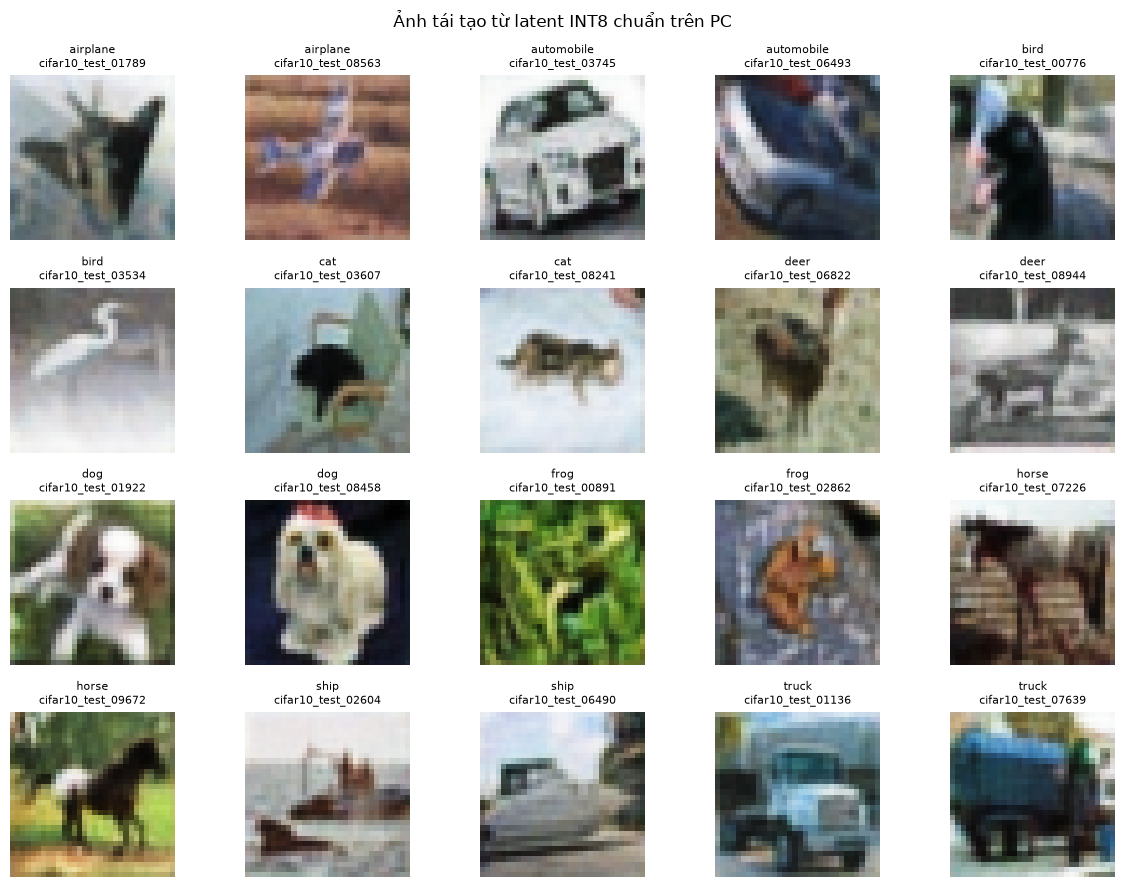

In [7]:
fig, axes = plt.subplots(4, 5, figsize=(12, 9))
for axis, record in zip(axes.flat, hardware_records):
    image_id = record['image_id']
    reconstruction = Image.open(reconstruction_dir / f'{image_id}.png')
    axis.imshow(reconstruction)
    axis.set_title(f"{record['class_name']}\n{image_id}", fontsize=8)
    axis.axis('off')
plt.suptitle('Ảnh tái tạo từ latent INT8 chuẩn trên PC')
plt.tight_layout()